In [1]:
import os
import time
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

Data Acquisition (Web Scraping)



In [2]:
def get_page(url):
    response = requests.get(url, timeout=20)
    response.raise_for_status()
    response.encoding = "utf-8"
    return BeautifulSoup(response.text, "html.parser")

In [3]:
def scrape_listing_page(page_number):
    url = f"https://books.toscrape.com/catalogue/page-{page_number}.html"
    soup = get_page(url)
    books = []
    for item in soup.find_all("article", class_="product_pod"):
        link = item.h3.a["href"]
        books.append({
            "title": item.h3.a["title"],
            "price_raw": item.find("p", class_="price_color").text,
            "rating_word": item.find("p", class_="star-rating")["class"][1],
            "availability_raw": item.find("p", class_="availability").text.strip(),
            "url": "https://books.toscrape.com/catalogue/" + link,
        })
    return books

# Test on page 1 first to make sure it works
test = scrape_listing_page(1)
print("Books found on page 1:", len(test))
test[0]

Books found on page 1: 20


{'title': 'A Light in the Attic',
 'price_raw': '£51.77',
 'rating_word': 'Three',
 'availability_raw': 'In stock',
 'url': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html'}

**Scrape one book's detail page.** This gets the genre, description, UPC (a unique ID) and stock quantity.

In [4]:
def scrape_detail_page(url):
    soup = get_page(url)
    breadcrumb = soup.find("ul", class_="breadcrumb").find_all("li")
    category = breadcrumb[2].text.strip()
    desc_heading = soup.find("div", id="product_description")
    if desc_heading is not None:
        description = desc_heading.find_next_sibling("p").text.strip()
    else:
        description = None

    table = {}
    for row in soup.find("table", class_="table-striped").find_all("tr"):
        table[row.th.text.strip()] = row.td.text.strip()

    return {
        "category": category,
        "description": description,
        "upc": table.get("UPC"),
        "availability_detail": table.get("Availability"),
    }

scrape_detail_page(test[0]["url"])

{'category': 'Poetry',
 'description': "It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love th It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love that Silverstein. Need proof of his genius? RockabyeRockabye baby, in the treetopDon't you know a treetopIs no safe place to rock?And who put you up there,And your cradle, too?Baby, I think someone down here'sGo

 This loops over all 50 pages, then over all 1,000 books. We pause briefly between requests to be polite to the website. The result is saved to a file so we only scrape once.

In [5]:
RAW_FILE = "books_raw.csv"

if os.path.exists(RAW_FILE):
    raw = pd.read_csv(RAW_FILE)
    print("Loaded saved data:", raw.shape)
else:
    all_books = []

    for page in range(1, 51):
        all_books.extend(scrape_listing_page(page))
        time.sleep(0.3)
    print("Listing pages done. Books found:", len(all_books))

    for i, book in enumerate(all_books, start=1):
        try:
            book.update(scrape_detail_page(book["url"]))
        except Exception as error:
            print("Problem with", book["title"], "-", error)
        if i % 100 == 0:
            print(i, "detail pages done")
        time.sleep(0.3)

    raw = pd.DataFrame(all_books)
    raw.to_csv(RAW_FILE, index=False)
    print("Saved", RAW_FILE, raw.shape)

raw.head()

Loaded saved data: (1000, 12)


,title,price_raw,rating_word,availability_raw,url,category,description,upc,availability_detail,n_reviews,price_excl_tax_raw,price_incl_tax_raw
0,A Light in the Attic,£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,Poetry,It's hard to imagine a world without A Light i...,a897fe39b1053632,In stock (22 available),0,£51.77,£51.77
1,Tipping the Velvet,£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,In stock (20 available),0,£53.74,£53.74
2,Soumission,£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...,Fiction,"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,In stock (20 available),0,£50.10,£50.10
3,Sharp Objects,£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,In stock (20 available),0,£47.82,£47.82
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,History,From a renowned historian comes a groundbreaki...,4165285e1663650f,In stock (20 available),0,£54.23,£54.23


we scraped all 50 listing pages and found 1,000 books. We then visited all 1,000 book pages. For each book we collected the title, price (GBP), star rating, availability, genre, description, UPC and stock quantity. and we had 0 errors

In [6]:
raw.info()
print()
print("Missing values per column:")
print(raw.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   title                1000 non-null   str  
 1   price_raw            1000 non-null   str  
 2   rating_word          1000 non-null   str  
 3   availability_raw     1000 non-null   str  
 4   url                  1000 non-null   str  
 5   category             1000 non-null   str  
 6   description          998 non-null    str  
 7   upc                  1000 non-null   str  
 8   availability_detail  1000 non-null   str  
 9   n_reviews            1000 non-null   int64
 10  price_excl_tax_raw   1000 non-null   str  
 11  price_incl_tax_raw   1000 non-null   str  
dtypes: int64(1), str(11)
memory usage: 93.9 KB

Missing values per column:
title                  0
price_raw              0
rating_word            0
availability_raw       0
url                    0
category               0
descrip

In [7]:
df = raw.copy()
df["price"] = df["price_raw"].str.replace(r"[^0-9.]", "", regex=True).astype(float)

rating_numbers = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
df["rating"] = df["rating_word"].map(rating_numbers)
df["stock_qty"] = df["availability_detail"].str.extract(r"(\d+)")[0].astype(float)
df["stock_qty"] = df["stock_qty"].fillna(0).astype(int)
df["in_stock"] = df["availability_raw"].str.contains("In stock").astype(int)

rows_before = len(df)
df = df.drop_duplicates(subset="upc")
print("Duplicates removed:", rows_before - len(df))

repeated = df[df["title"].duplicated(keep=False)]
print("Books that share a title:", len(repeated))
print(repeated[["title", "price", "upc"]])

df["category"] = df["category"].replace({"Default": "Unlabelled", "Add a comment": "Unlabelled"})
print("Unlabelled books:", (df["category"] == "Unlabelled").sum())

df["has_description"] = df["description"].notnull().astype(int)
df["description"] = df["description"].fillna("")

df["desc_length"] = df["description"].str.len()
df["title_length"] = df["title"].str.len()

print("Missing descriptions:", (df["has_description"] == 0).sum())
df[["title", "category", "price", "rating", "stock_qty", "desc_length"]].head()

Duplicates removed: 0
Books that share a title: 2
                      title  price               upc
236  The Star-Touched Queen  46.02  1528279aec1f3dce
358  The Star-Touched Queen  32.30  4a7a25be293ad678
Unlabelled books: 219
Missing descriptions: 2


,title,category,price,rating,stock_qty,desc_length
0,A Light in the Attic,Poetry,51.77,3,22,1017
1,Tipping the Velvet,Historical Fiction,53.74,1,20,1029
2,Soumission,Fiction,50.10,1,20,1093
3,Sharp Objects,Mystery,47.82,4,20,1635
4,Sapiens: A Brief History of Humankind,History,54.23,5,20,1945


In [8]:
print("Any missing prices?  ", df["price"].isnull().sum())
print("Any missing ratings? ", df["rating"].isnull().sum())
print("Price range:", df["price"].min(), "to", df["price"].max())
print("Unique values of in_stock:", df["in_stock"].unique())

final_columns = ["title", "upc", "category", "price", "rating", "stock_qty",
                 "has_description", "desc_length", "title_length", "description", "url"]
clean = df[final_columns].reset_index(drop=True)
clean.to_csv("books_clean.csv", index=False)
print("Saved books_clean.csv with", len(clean), "books")
clean.describe()

Any missing prices?   0
Any missing ratings?  0
Price range: 10.0 to 59.99
Unique values of in_stock: [1]
Saved books_clean.csv with 1000 books


,price,rating,stock_qty,has_description,desc_length,title_length
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.07035,2.923000,8.585000,0.998000,1431.628000,39.097000
std,14.44669,1.434967,5.654622,0.044699,669.324296,25.752724
min,10.00000,1.000000,1.000000,0.000000,0.000000,2.000000
25%,22.10750,2.000000,3.000000,1.000000,1069.750000,19.000000
50%,35.98000,3.000000,7.000000,1.000000,1348.500000,35.000000
75%,47.45750,4.000000,14.000000,1.000000,1681.500000,53.000000
max,59.99000,5.000000,22.000000,1.000000,8646.000000,204.000000


After cleaning we still have 1,000 books. there were no duplicates . "The Star-Touched Queen" appears twice, but the two rows have different UPCs and prices, so they are separate listings and we kept both. Only 2 books had no description. There are 48 real genres, and many have fewer than 10 books. Every book is "In stock", so `in_stock` is the same for all books and cannot help predict price. The stock quantity has a difference (21 different values), so we use that.The website shows 0 reviews for every book, so we did not use review counts.

Data Visualisation and Exploration



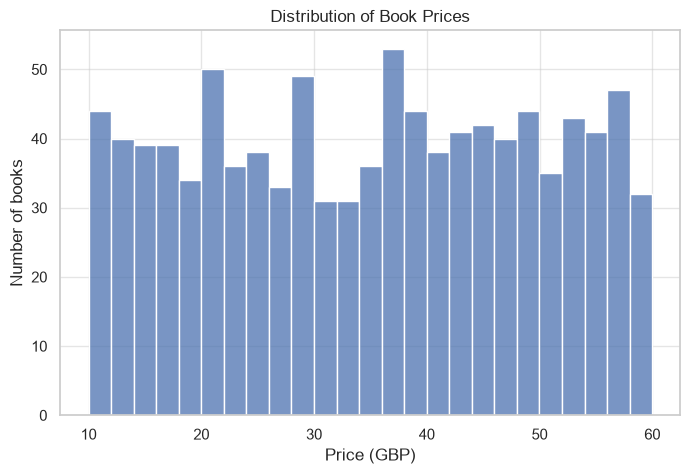

Average price: £ 35.07
Cheapest: £ 10.0 | Most expensive: £ 59.99


In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(clean["price"], bins=25)
plt.title("Distribution of Book Prices")
plt.xlabel("Price (GBP)")
plt.ylabel("Number of books")
plt.show()

print("Average price: £", round(clean["price"].mean(), 2))
print("Cheapest: £", clean["price"].min(), "| Most expensive: £", clean["price"].max())

prices go from 10.00 to 59.99 pounds, with an average of 35.07 and a median of 35.98 pounds. The quartiles are evenly spaced, so the books are spread fairly evenly across the whole range instead of bunching around one price.

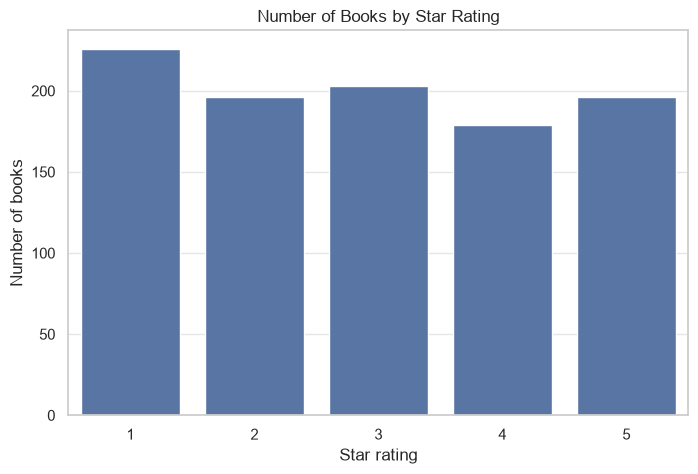

In [10]:
plt.figure(figsize=(8, 5))
sns.countplot(x="rating", data=clean)
plt.title("Number of Books by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Number of books")
plt.show()

every star rating has a similar number of books: 226 one-star, 196 two-star, 203 three-star, 179 four-star and 196 five-star. The ratings are spread fairly evenly.

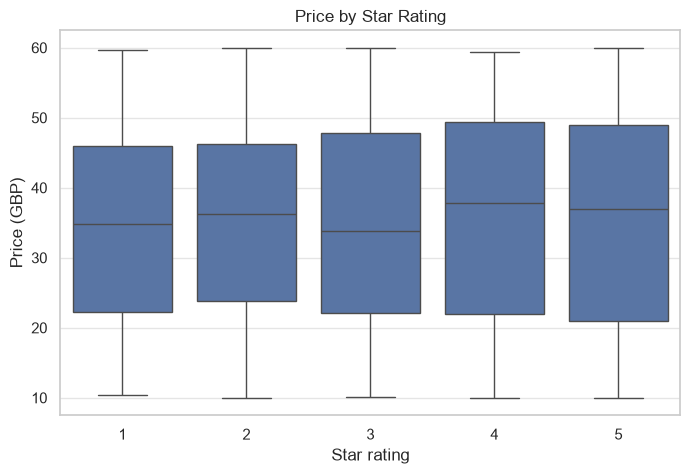

rating
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: price, dtype: float64


In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="rating", y="price", data=clean)
plt.title("Price by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Price (GBP)")
plt.show()

print(clean.groupby("rating")["price"].mean().round(2))

the average price barely changes with rating, 34.56pounds for 1-star, 34.81pounds for 2-star, 34.69 for 3-star, 36.09 for 4-star and 35.37 for 5-star. The biggest gap is only 1.53, while prices inside each rating vary by about 14pounds. The boxes overlap a lot. So a higher star rating does not mean a higher price.

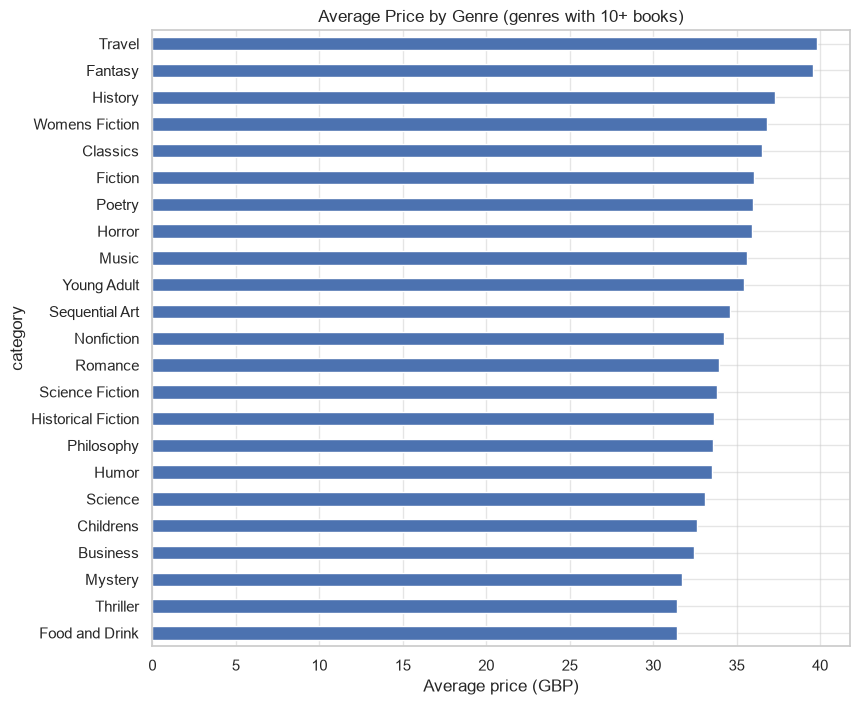

Cheapest genre: Food and Drink - £ 31.41
Most expensive genre: Travel - £ 39.79


In [12]:
real_genres = clean[clean["category"] != "Unlabelled"]
genre_stats = real_genres.groupby("category")["price"].agg(["count", "mean"])
genre_stats = genre_stats[genre_stats["count"] >= 10].sort_values("mean")

plt.figure(figsize=(9, 8))
genre_stats["mean"].plot(kind="barh")
plt.title("Average Price by Genre (genres with 10+ books)")
plt.xlabel("Average price (GBP)")
plt.show()

print("Cheapest genre:", genre_stats.index[0], "- £", round(genre_stats["mean"].iloc[0], 2))
print("Most expensive genre:", genre_stats.index[-1], "- £", round(genre_stats["mean"].iloc[-1], 2))

only the 23 genres with at least 10 books are shown, because the average from one or two books is not reliable. The cheapest genre on average is Food and Drink (31.41 pounds) and the most expensive is Travel (39.79 pounds), a gap of 8.38 pounds. That gap is small compared with how much prices vary inside each genre (about 14 pounds). Some of these genres are small (Travel has 11 books), so the differences could be chance.

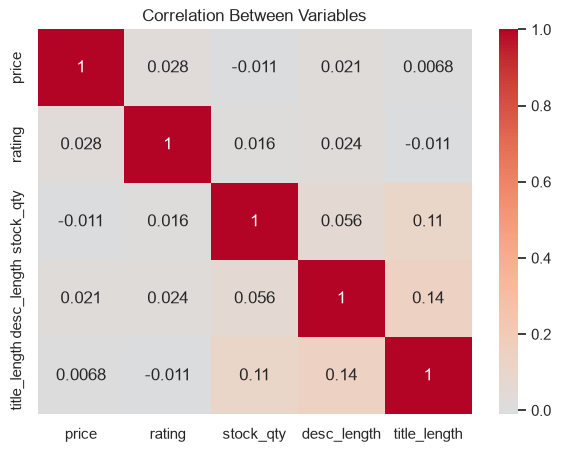

In [13]:
number_columns = ["price", "rating", "stock_qty", "desc_length", "title_length"]

plt.figure(figsize=(7, 5))
sns.heatmap(clean[number_columns].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Between Variables")
plt.show()

the rating according to the price is closer to negative and between negative 1 and 1 in the correlation

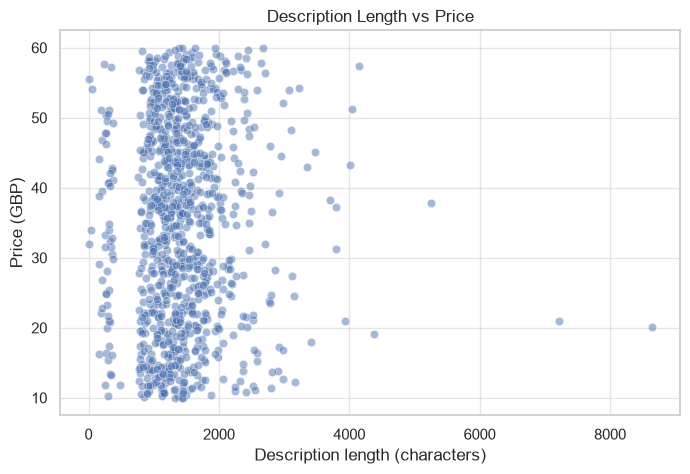

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="desc_length", y="price", data=clean, alpha=0.5)
plt.title("Description Length vs Price")
plt.xlabel("Description length (characters)")
plt.ylabel("Price (GBP)")
plt.show()

the scatter plot between 0-2000 description shows a bundled up plot according to pricing then moves to a clear plot with less pricing as the description length goes up

price is spread evenly between 10 and 60 pounds. Rating, genre and description length have little or no link with price. Genre shows the biggest differences, but they are small compared with the variation inside each genre.

Predictive Modelling (Linear Regression)

**What is linear regression?** It draws the best straight-line relationship between inputs (called *features*) and the thing we want to predict (called the *target*). Here the target is **price**.


In [15]:
model_data = clean.copy()


genre_counts = model_data["category"].value_counts()
small_genres = genre_counts[genre_counts < 10].index
model_data["genre"] = model_data["category"].replace(small_genres, "Other")


genre_columns = pd.get_dummies(model_data["genre"], prefix="genre", drop_first=True, dtype=int)

X = pd.concat([model_data[["rating", "stock_qty", "desc_length"]], genre_columns], axis=1)
y = model_data["price"]

print("Number of books:", len(X))
print("Number of features:", X.shape[1])
X.head()

Number of books: 1000
Number of features: 27


,rating,stock_qty,desc_length,genre_Childrens,genre_Classics,genre_Fantasy,genre_Fiction,genre_Food and Drink,genre_Historical Fiction,genre_History,...,genre_Poetry,genre_Romance,genre_Science,genre_Science Fiction,genre_Sequential Art,genre_Thriller,genre_Travel,genre_Unlabelled,genre_Womens Fiction,genre_Young Adult
0,3,22,1017,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1,1,20,1029,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,1,20,1093,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,20,1635,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,20,1945,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


**Train/test split.** We hide 20% of the books from the model while it learns (the *test set*). Then we check how well it predicts books it has never seen. This is a fair test of whether the model really works.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training books:", len(X_train))
print("Testing books: ", len(X_test))

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

Training books: 800
Testing books:  200


In [17]:
baseline_predictions = np.full(len(y_test), y_train.mean())

def evaluate(name, actual, predicted):
    return {
        "Model": name,
        "MAE (£)": round(mean_absolute_error(actual, predicted), 2),
        "RMSE (£)": round(np.sqrt(mean_squared_error(actual, predicted)), 2),
        "R²": round(r2_score(actual, predicted), 3),
    }

results = pd.DataFrame([
    evaluate("Baseline (always guess the average)", y_test, baseline_predictions),
    evaluate("Linear regression", y_test, predictions),
])
results

,Model,MAE (£),RMSE (£),R²
0,Baseline (always guess the average),12.66,14.53,-0.005
1,Linear regression,12.93,14.93,-0.061


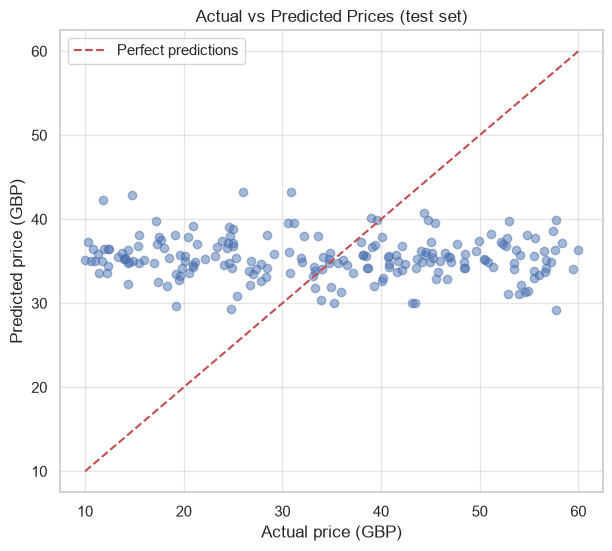

In [18]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions, alpha=0.5)
line = [y.min(), y.max()]
plt.plot(line, line, "r--", label="Perfect predictions")
plt.xlabel("Actual price (GBP)")
plt.ylabel("Predicted price (GBP)")
plt.title("Actual vs Predicted Prices (test set)")
plt.legend()
plt.show()

Each coefficient is the change in predicted price when that feature goes up by 1, with the others held the same.

In [19]:
coefficients = pd.Series(model.coef_, index=X.columns).sort_values()
print("Intercept (starting price):", round(model.intercept_, 2))
print()
print("Biggest negative effects:")
print(coefficients.head(5).round(2))
print()
print("Biggest positive effects:")
print(coefficients.tail(5).round(2))
print()
print("Rating coefficient:", round(coefficients["rating"], 2))
print("Stock coefficient: ", round(coefficients["stock_qty"], 3))

Intercept (starting price): 27.55

Biggest negative effects:
desc_length        0.00
stock_qty          0.02
genre_Mystery      0.19
rating             0.29
genre_Childrens    1.27
dtype: float64

Biggest positive effects:
genre_Horror      7.48
genre_Poetry      7.62
genre_Fantasy     9.71
genre_Travel     10.45
genre_Humor      12.51
dtype: float64

Rating coefficient: 0.29
Stock coefficient:  0.024


In [20]:
feature_options = {
    "Rating only": ["rating"],
    "Rating + stock + description length": ["rating", "stock_qty", "desc_length"],
    "All features (with genre)": list(X.columns),
}

rows = []
for name, columns in feature_options.items():
    m = LinearRegression().fit(X_train[columns], y_train)
    p = m.predict(X_test[columns])
    rows.append({"Features used": name,
                 "MAE (£)": round(mean_absolute_error(y_test, p), 2),
                 "R²": round(r2_score(y_test, p), 3)})

pd.DataFrame(rows)

,Features used,MAE (£),R²
0,Rating only,12.66,-0.007
1,Rating + stock + description length,12.70,-0.011
2,All features (with genre),12.93,-0.061
